# 05 · ¿Qué clientes volverán a comprar? (KNN)

**Pregunta de negocio 4:** ¿qué clientes volverán a comprar en los próximos 90 días?

Datos: `tabla_recompra(fecha_corte)` de `src/features.py`. Una fila por cliente con variables
calculadas **solo con pedidos anteriores a la fecha de corte** y la etiqueta `volvera` (1 si tiene al
menos un pedido completado en los 90 días siguientes al corte), calculada **solo con pedidos desde
el corte**.

> Requisito: haber ejecutado `python src/generar_datos.py` y `python src/limpieza.py`.
>
> **Reglas del notebook (para no hacer trampas):**
> 1. **Nada del futuro:** ninguna variable usa pedidos de fecha ≥ corte (se comprueba con un assert).
> 2. **Nada de las semanas anteriores:** ni los segmentos de la S7 ni los resultados de la S8. Se
>    calcularon con todos los datos hasta octubre, así que "saben" lo que pasó después de cada corte.
> 3. **La prueba se mira una sola vez**, en la sección 7. Las variables, k, el umbral y el modelo
>    elegido salen antes, solo de la validación cruzada del entrenamiento.
> 4. La lista real de tipos de cliente del generador **solo** se lee en la sección 9 (comprobación
>    informativa, no se usa para nada más).

## 0. Configuración

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve, brier_score_loss)
from sklearn.model_selection import (GridSearchCV, KFold, StratifiedGroupKFold, cross_val_predict,
                                     cross_val_score)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

# El notebook se ejecuta desde notebooks/: src está en ../src
RAIZ = Path.cwd().parent
sys.path.append(str(RAIZ / "src"))
from bd import leer_sql, ventas_por_linea  # noqa: E402
from features import VARIABLES_RECOMPRA, tabla_recompra  # noqa: E402

SEMILLA = 42
HORIZONTE = 90
CARPETA_IMG = RAIZ / "docs" / "img"
CARPETA_IMG.mkdir(parents=True, exist_ok=True)
CARPETA_MODELOS = RAIZ / "models"
CARPETA_MODELOS.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
AZUL, NARANJA, VERDE_AGUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)


def euros(valor, decimales=0):
    """12345.6 -> '12.346 €' (formato español)."""
    texto = f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"{texto} €"


def num(valor, decimales=2):
    """1234.567 -> '1.234,57' (número en formato español, sin unidad)."""
    return f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def pct(valor, decimales=1):
    """0.1234 -> '12,3 %'."""
    return f"{num(100 * valor, decimales)} %"


def guardar(fig, nombre):
    """Guarda la figura en docs/img/recompra_<nombre>.png.

    metadata={"Software": None} quita la versión de matplotlib del PNG: con los mismos datos,
    el archivo es idéntico byte a byte entre ejecuciones.
    """
    fig.savefig(CARPETA_IMG / f"recompra_{nombre}.png", dpi=120, bbox_inches="tight",
                metadata={"Software": None})

### Cómo funciona una fecha de corte

Para cada **fecha de corte** nos ponemos en la piel de la tienda ese día:

- **Ventana de variables (el pasado):** todos los pedidos con fecha **anterior** al corte. Con ellos
  se calculan la recencia, la frecuencia, el gasto, etc. Es lo único que la tienda sabría ese día.
- **Ventana de la etiqueta (el futuro):** los **90 días desde el corte**, `[corte, corte + 90)`. Si el
  cliente hace al menos un pedido completado ahí, `volvera = 1`.

```
            pasado (variables)                 │ futuro (etiqueta)
 ──────────────────────────────────────────────┼──────────────────────►  tiempo
 alta del cliente ... pedidos ... pedidos      │ ¿algún pedido completado
                                               │  en estos 90 días?
                                          fecha de corte
```

Repetir esto con varias fechas de corte da varios "fotogramas" de los mismos clientes. El gráfico
muestra las que se usan aquí.

Pedidos desde 2024-11-04 hasta 2026-10-31
Último corte posible con 90 días de futuro: 2026-08-03


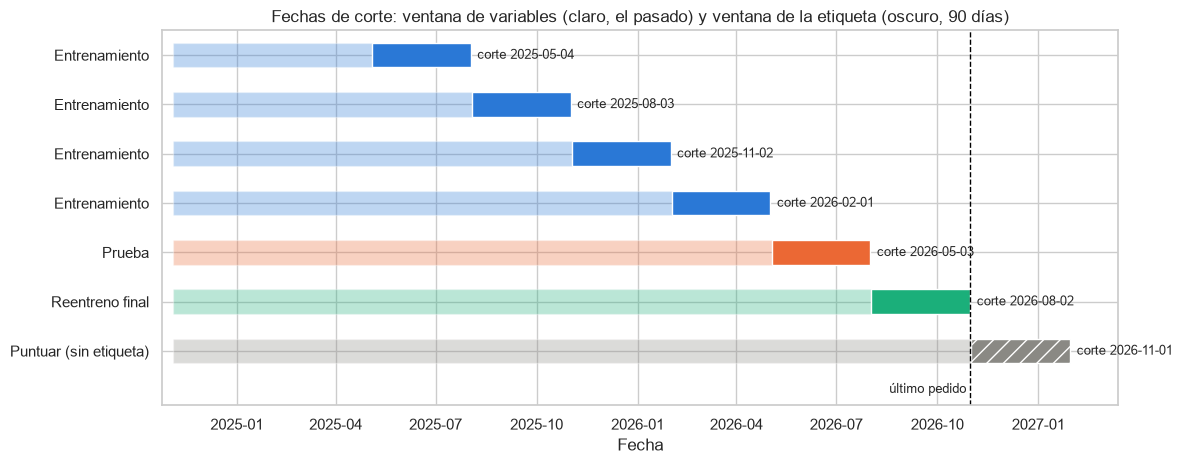

In [2]:
CORTES_TRAIN = ["2025-05-04", "2025-08-03", "2025-11-02", "2026-02-01"]
CORTE_TEST = "2026-05-03"
CORTES_FINAL = CORTES_TRAIN + [CORTE_TEST, "2026-08-02"]   # todos los cortes con etiqueta (sección 8)
CORTE_PUNTUAR = "2026-11-01"                                # datos más recientes, sin etiqueta todavía

# Primer y último pedido de la base de datos (para dibujar el pasado y comprobar el último corte)
fechas = leer_sql("SELECT MIN(fecha_pedido) AS primero, MAX(fecha_pedido) AS ultimo FROM pedidos")
PRIMER_PEDIDO = pd.Timestamp(fechas.loc[0, "primero"])
DATOS_HASTA = pd.Timestamp(fechas.loc[0, "ultimo"]).normalize()
print("Pedidos desde", PRIMER_PEDIDO.date(), "hasta", DATOS_HASTA.date())

# El último corte con etiqueta completa necesita 90 días de datos después
ultimo_corte_posible = DATOS_HASTA + pd.Timedelta(days=1) - pd.Timedelta(days=HORIZONTE)
print("Último corte posible con 90 días de futuro:", ultimo_corte_posible.date())
assert pd.Timestamp(CORTES_FINAL[-1]) <= ultimo_corte_posible

filas = ([("Entrenamiento", c) for c in CORTES_TRAIN] + [("Prueba", CORTE_TEST)]
         + [("Reentreno final", "2026-08-02"), ("Puntuar (sin etiqueta)", CORTE_PUNTUAR)])
fig, ax = plt.subplots(figsize=(12, 4.8))
colores_fila = {"Entrenamiento": AZUL, "Prueba": NARANJA, "Reentreno final": VERDE_AGUA,
                "Puntuar (sin etiqueta)": GRIS}
for i, (tipo, c) in enumerate(filas):
    corte = pd.Timestamp(c)
    y_fila = len(filas) - 1 - i
    ax.barh(y_fila, (corte - PRIMER_PEDIDO).days, left=PRIMER_PEDIDO, height=0.5, color=colores_fila[tipo], alpha=0.30)
    ax.barh(y_fila, HORIZONTE, left=corte, height=0.5, color=colores_fila[tipo],
            hatch="//" if tipo.startswith("Puntuar") else None, edgecolor="white")
    ax.text(corte + pd.Timedelta(days=HORIZONTE + 6), y_fila, f"corte {c}", va="center", fontsize=9)
ax.axvline(DATOS_HASTA, color="black", ls="--", lw=1)
ax.text(DATOS_HASTA, -0.85, "último pedido ", ha="right", fontsize=9)
ax.set_ylim(-1.1, len(filas) - 0.5)
ax.set_yticks(range(len(filas)), [f"{t}" for t, _ in filas][::-1])
ax.set_xlabel("Fecha")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set_title("Fechas de corte: ventana de variables (claro, el pasado) y ventana de la etiqueta (oscuro, 90 días)")
ax.set_xlim(PRIMER_PEDIDO - pd.Timedelta(days=10), pd.Timestamp("2027-03-15"))
fig.tight_layout()
guardar(fig, "cortes")
plt.show()

**Conclusión.** Las ventanas de la etiqueta (las barras oscuras) no se pisan: cada corte está 91 días
después del anterior. La de la prueba (naranja) empieza después de que termine la última del
entrenamiento, y la del corte del 2026-11-01 está rayada porque ese futuro aún no ha pasado: esos
clientes se puntúan, no se evalúan. La ventana de variables (barra clara) sí se solapa con el
futuro de los cortes anteriores, y es correcto: el 2026-05-03 la tienda ya conoce lo que pasó en
2025.

## 1. Los datasets por fecha de corte

Se apilan los cuatro cortes de entrenamiento y se deja el de la prueba aparte.

**Clientes sin ningún pedido completado antes del corte:** se quedan fuera. No tienen recencia ni
ticket medio y la pregunta es si un cliente **volverá**, algo que no aplica a quien nunca ha
comprado (para ellos haría falta una campaña de bienvenida, no de retención). Se cuentan en la tabla.

In [3]:
train = pd.concat([tabla_recompra(c, HORIZONTE) for c in CORTES_TRAIN], ignore_index=True)
test = tabla_recompra(CORTE_TEST, HORIZONTE)

# Assert: ninguna ventana de etiqueta del entrenamiento entra en el periodo de la prueba
inicio_prueba = pd.Timestamp(CORTE_TEST)
for c in CORTES_TRAIN:
    fin_etiqueta = pd.Timestamp(c) + pd.Timedelta(days=HORIZONTE)   # la ventana es [c, fin)
    assert fin_etiqueta <= inicio_prueba, f"La etiqueta del corte {c} entra en la prueba"
print("OK: todas las ventanas de etiqueta del entrenamiento terminan antes del", CORTE_TEST)

resumen = []
for c in CORTES_TRAIN + [CORTE_TEST]:
    t = tabla_recompra(c, HORIZONTE)
    resumen.append({"corte": c, "uso": "prueba" if c == CORTE_TEST else "entrenamiento",
                    "etiqueta hasta": t.attrs["ultimo_dia_etiqueta"], "clientes": len(t),
                    "sin compras antes (fuera)": t.attrs["n_sin_compras_antes"],
                    "volverán": int(t["volvera"].sum()), "% volvera = 1": round(100 * t["volvera"].mean(), 1)})
resumen = pd.DataFrame(resumen)
print(f"Entrenamiento: {len(train)} filas de {train['id_cliente'].nunique()} clientes distintos · "
      f"{pct(train['volvera'].mean())} con volvera = 1")
print(f"Prueba: {len(test)} filas · {pct(test['volvera'].mean())} con volvera = 1")
resumen

OK: todas las ventanas de etiqueta del entrenamiento terminan antes del 2026-05-03
Entrenamiento: 1142 filas de 381 clientes distintos · 58,7 % con volvera = 1
Prueba: 418 filas · 55,5 % con volvera = 1


,corte,uso,etiqueta hasta,clientes,sin compras antes (fuera),volverán,% volvera = 1
0,2025-05-04,entrenamiento,2025-08-01,176,14,114,64.8
1,2025-08-03,entrenamiento,2025-10-31,253,24,142,56.1
2,2025-11-02,entrenamiento,2026-01-30,332,26,201,60.5
3,2026-02-01,entrenamiento,2026-05-01,381,20,213,55.9
4,2026-05-03,prueba,2026-07-31,418,26,232,55.5


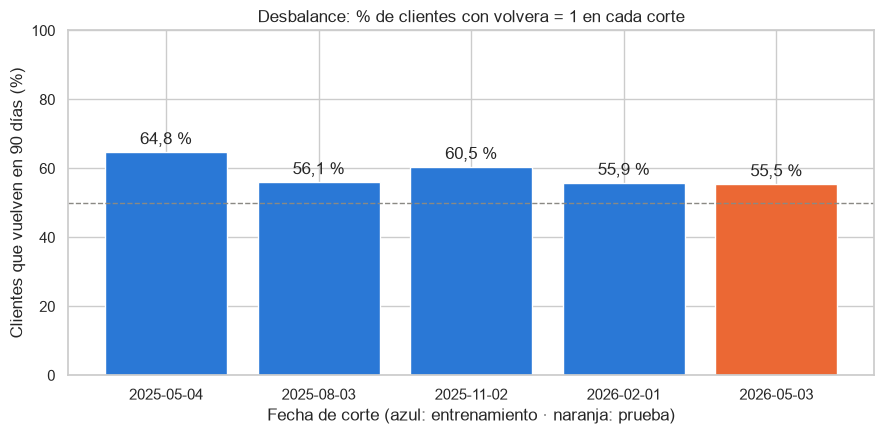

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colores = [NARANJA if u == "prueba" else AZUL for u in resumen["uso"]]
barras = ax.bar(resumen["corte"], resumen["% volvera = 1"], color=colores)
ax.bar_label(barras, labels=[f"{num(v, 1)} %" for v in resumen["% volvera = 1"]], padding=3)
ax.axhline(50, color=GRIS, ls="--", lw=1)
ax.set_ylim(0, 100)
ax.set_xlabel("Fecha de corte (azul: entrenamiento · naranja: prueba)")
ax.set_ylabel("Clientes que vuelven en 90 días (%)")
ax.set_title("Desbalance: % de clientes con volvera = 1 en cada corte")
fig.tight_layout()
guardar(fig, "desbalance")
plt.show()

**Conclusión.** La clase "volverá" es algo mayoritaria en todos los cortes, pero el desbalance es
leve (nada que ver con el 1 % de anomalías de la S8). Aun así, el accuracy de "decir siempre que
volverá" ya parte de más del 50 %, así que hay que compararlo siempre con esa referencia.

### Prueba de fuga: ¿alguna variable mira el futuro?

Se recalculan **todas** las variables y la etiqueta con pandas, filtrando a mano las fechas a partir
de `ventas_por_linea()` (otra consulta, sin las CTE de `tabla_recompra()`), y se comparan con las de
la función. Se hace para todos los cortes del notebook.

In [5]:
lineas = ventas_por_linea()
por_pedido = (lineas.groupby(["id_pedido", "id_cliente", "fecha_pedido", "estado", "fecha_alta"], as_index=False)
              ["importe"].sum())


def recompra_a_mano(corte, horizonte=HORIZONTE):
    """Las mismas variables que tabla_recompra(), con pandas y filtros de fecha explícitos."""
    corte = pd.Timestamp(corte)
    pasado = por_pedido[por_pedido["fecha_pedido"] < corte]              # solo el pasado
    futuro = por_pedido[(por_pedido["fecha_pedido"] >= corte)             # solo el futuro
                        & (por_pedido["fecha_pedido"] < corte + pd.Timedelta(days=horizonte))
                        & (por_pedido["estado"] == "completado")]
    comp = pasado[pasado["estado"] == "completado"]
    g = comp.groupby("id_cliente")
    t = pd.DataFrame({"frecuencia": g.size(), "monetario": g["importe"].sum(), "ultimo": g["fecha_pedido"].max(),
                      "alta": g["fecha_alta"].first()})
    t = t[t["alta"] < corte]
    t["recencia_dias"] = (corte - t["ultimo"]).dt.days
    dias_alta = (corte - t["alta"]).dt.total_seconds() / 86400
    t["antiguedad_dias"] = dias_alta.astype(int)
    t["pedidos_por_mes"] = t["frecuencia"] / np.maximum(dias_alta / 30.4375, 1.0)
    t["ticket_medio"] = t["monetario"] / t["frecuencia"]
    t["pedidos_ultimos_90d"] = (comp[comp["fecha_pedido"] >= corte - pd.Timedelta(days=90)]
                                .groupby("id_cliente").size().reindex(t.index, fill_value=0))
    todos = pasado.groupby("id_cliente")["estado"]
    t["pct_cancelados_devueltos"] = 100 * todos.apply(lambda e: e.isin(["cancelado", "devuelto"]).mean()).reindex(t.index)
    t["volvera"] = t.index.isin(futuro["id_cliente"]).astype(int)
    return t.sort_index()


for c in CORTES_FINAL + [CORTE_PUNTUAR]:
    funcion = tabla_recompra(c).set_index("id_cliente")
    mano = recompra_a_mano(c)
    assert funcion.index.equals(mano.index), c
    for v in VARIABLES_RECOMPRA + ["volvera"]:
        assert np.allclose(funcion[v], mano[v]), (c, v)
    # Y la comprobación directa: el último pedido usado está siempre antes del corte
    assert (pd.Timestamp(c) - pd.to_timedelta(funcion["recencia_dias"], unit="D") < pd.Timestamp(c)).all()
print(f"OK: en los {len(CORTES_FINAL) + 1} cortes, las 8 variables y la etiqueta coinciden con el cálculo a mano.")
print("Ninguna variable usa pedidos de fecha ≥ corte.")

OK: en los 7 cortes, las 8 variables y la etiqueta coinciden con el cálculo a mano.
Ninguna variable usa pedidos de fecha ≥ corte.


## 2. Validación cruzada sin fugas: `StratifiedGroupKFold` por cliente

En el entrenamiento, un mismo cliente aparece hasta 4 veces (una por corte). Con un `KFold` normal,
la fila de un cliente en el corte de mayo podría ir a validación mientras su fila de agosto está en
entrenamiento. Su comportamiento es muy parecido de un corte a otro, así que el modelo "lo reconoce"
en lugar de generalizar a clientes nuevos, y la métrica sale **demasiado optimista**.

`StratifiedGroupKFold` usa `id_cliente` como **grupo**: todas las filas de un cliente caen en el mismo
pliegue. Además intenta mantener el mismo % de `volvera = 1` en cada pliegue (estratificado).

In [6]:
X_train, y_train, grupos = train[VARIABLES_RECOMPRA], train["volvera"], train["id_cliente"]
X_test, y_test = test[VARIABLES_RECOMPRA], test["volvera"]

CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
KFOLD = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

# ¿Cuántas filas de validación tienen al mismo cliente en el entrenamiento de ese pliegue?
for nombre, cv in [("KFold normal", KFOLD), ("StratifiedGroupKFold", CV)]:
    repetidas = []
    for i_tr, i_va in cv.split(X_train, y_train, groups=grupos):
        repetidas.append(grupos.iloc[i_va].isin(grupos.iloc[i_tr]).mean())
    print(f"{nombre:<22}: {pct(np.mean(repetidas))} de las filas de validación tienen al mismo cliente en entrenamiento")
print("Filas por cliente en el entrenamiento:", grupos.value_counts().value_counts().sort_index().to_dict())

KFold normal          : 90,8 % de las filas de validación tienen al mismo cliente en entrenamiento
StratifiedGroupKFold  : 0,0 % de las filas de validación tienen al mismo cliente en entrenamiento
Filas por cliente en el entrenamiento: {1: 49, 2: 79, 3: 77, 4: 176}


C:\Users\USUARIO\Documents\tienda-analytics\.venv\Lib\site-packages\sklearn\model_selection\_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(


**Las variables con cola larga van con `log1p`** (como en la S7). Se decide solo con el entrenamiento:
las que tienen una asimetría mayor que 1.

In [7]:
asimetria = X_train.skew()
VARIABLES_LOG = list(asimetria[asimetria > 1].index)
print("Asimetría en el entrenamiento:")
print(asimetria.round(2).to_string())
print("\nCon log1p:", VARIABLES_LOG)


def hacer_pipeline(variables, modelo):
    """ColumnTransformer (log1p en las de cola larga) -> StandardScaler -> modelo."""
    con_log = [v for v in variables if v in VARIABLES_LOG]
    sin_log = [v for v in variables if v not in VARIABLES_LOG]
    preparar = ColumnTransformer([
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), con_log),
        ("tal_cual", "passthrough", sin_log),
    ])
    return Pipeline([("preparar", preparar), ("escalar", StandardScaler()), ("modelo", modelo)])

Asimetría en el entrenamiento:
recencia_dias               1.67
frecuencia                  3.06
monetario                   3.42
antiguedad_dias             0.38
pedidos_por_mes             2.30
ticket_medio                5.59
pedidos_ultimos_90d         1.68
pct_cancelados_devueltos    1.69

Con log1p: ['recencia_dias', 'frecuencia', 'monetario', 'pedidos_por_mes', 'ticket_medio', 'pedidos_ultimos_90d', 'pct_cancelados_devueltos']


In [8]:
# El efecto en la métrica: KNN con distintos k validado de las dos formas
filas = []
for k in [1, 5, 15, 45]:
    knn = hacer_pipeline(VARIABLES_RECOMPRA, KNeighborsClassifier(n_neighbors=k))
    auc_kfold = cross_val_score(knn, X_train, y_train, cv=KFOLD, scoring="roc_auc").mean()
    auc_grupos = cross_val_score(knn, X_train, y_train, groups=grupos, cv=CV, scoring="roc_auc").mean()
    filas.append({"k": k, "ROC-AUC KFold normal": round(auc_kfold, 3), "ROC-AUC por grupos": round(auc_grupos, 3),
                  "diferencia": round(auc_kfold - auc_grupos, 3)})
pd.DataFrame(filas)

,k,ROC-AUC KFold normal,ROC-AUC por grupos,diferencia
0,1,0.707,0.711,-0.004
1,5,0.820,0.823,-0.004
2,15,0.844,0.843,0.000
3,45,0.836,0.834,0.002


**Conclusión.** Con `KFold` normal, el 90,8 % de las filas de validación tienen al mismo cliente en
el entrenamiento; con `StratifiedGroupKFold`, el 0,0 %. Aun así, **aquí la diferencia en la métrica
es mínima** (entre −0,004 y 0,002). La razón: los cortes están separados 91 días y en ese tiempo
cambian la recencia, la frecuencia, la antigüedad y los pedidos de los últimos 90 días, así que la
fila de otro corte no es una copia del mismo cliente. El riesgo no desaparece (con cortes más
juntos o variables más estables las filas serían casi idénticas), así que se sigue usando la
validación por grupos: es la que mide si el modelo funciona con clientes que no ha visto.

## 3. Referencias (baselines) antes de KNN

Un modelo solo vale la pena si mejora lo que se podría hacer sin él:

1. **`DummyClassifier`** (clase mayoritaria): dice siempre "volverá". Es el suelo del accuracy.
2. **Regla de negocio:** "volverá si compró en los últimos 90 días" (`pedidos_ultimos_90d > 0`). Es lo
   que haría alguien de marketing sin modelo.
3. **`LogisticRegression`** con las 8 variables (mismo log1p y escalado). Es el modelo sencillo de
   referencia.

In [9]:
dummy = DummyClassifier(strategy="most_frequent")
logistica = hacer_pipeline(VARIABLES_RECOMPRA, LogisticRegression(max_iter=1000))


def regla_negocio(X):
    """1 (volverá) si tiene algún pedido completado en los 90 días anteriores al corte."""
    return (X["pedidos_ultimos_90d"] > 0).astype(int).to_numpy()


cv_ref = {}
cv_ref["Dummy (mayoritaria)"] = cross_val_score(dummy, X_train, y_train, groups=grupos, cv=CV, scoring="roc_auc")
# La regla no se entrena: su ROC-AUC por pliegue se calcula directamente sobre cada validación
cv_ref["Regla: compró en 90 días"] = np.array([
    roc_auc_score(y_train.iloc[i_va], regla_negocio(X_train.iloc[i_va]))
    for _, i_va in CV.split(X_train, y_train, groups=grupos)])
cv_ref["Regresión logística"] = cross_val_score(logistica, X_train, y_train, groups=grupos, cv=CV, scoring="roc_auc")
tabla_ref = pd.DataFrame({"ROC-AUC (media CV)": {n: v.mean() for n, v in cv_ref.items()},
                          "desviación": {n: v.std() for n, v in cv_ref.items()}}).round(3)
tabla_ref

,ROC-AUC (media CV),desviación
Dummy (mayoritaria),0.500,0.000
Regla: compró en 90 días,0.733,0.015
Regresión logística,0.840,0.014


**Conclusión.** El Dummy da 0,5 (no ordena a nadie). La regla, al ser un sí/no, solo puede separar
en dos grupos, y aun así ordena bastante mejor que el azar. La regresión logística, con las 8
variables continuas, es la marca que KNN tiene que superar.

## 4. KNN: búsqueda de k, pesos y métrica

Pipeline: `ColumnTransformer` (log1p) → `StandardScaler` → `KNeighborsClassifier`. El escalado es
imprescindible en KNN: sin él, el gasto en euros (miles) dominaría la distancia frente al nº de
pedidos (decenas).

`GridSearchCV` con la validación por grupos: k de 1 a 75 (impares), `weights` = uniform (todos los
vecinos votan igual) o distance (votan más los cercanos), métrica euclidea o manhattan. Se optimiza
ROC-AUC. Aquí con las 8 variables; la sección 5 compara conjuntos.

In [10]:
REJILLA = {
    "modelo__n_neighbors": list(range(1, 76, 2)),
    "modelo__weights": ["uniform", "distance"],
    "modelo__metric": ["euclidean", "manhattan"],
}


def buscar_knn(variables):
    """GridSearchCV de KNN con las variables dadas, validación por grupos y ROC-AUC."""
    busqueda = GridSearchCV(hacer_pipeline(variables, KNeighborsClassifier()), REJILLA, cv=CV,
                            scoring="roc_auc", return_train_score=True)
    busqueda.fit(X_train[variables], y_train, groups=grupos)
    return busqueda


busqueda_completo = buscar_knn(VARIABLES_RECOMPRA)
res = pd.DataFrame(busqueda_completo.cv_results_)
print("Mejor combinación (8 variables):", busqueda_completo.best_params_)
print("ROC-AUC de validación:", num(busqueda_completo.best_score_, 3))
(res.sort_values("rank_test_score")
    [["param_modelo__n_neighbors", "param_modelo__weights", "param_modelo__metric", "mean_train_score", "mean_test_score", "std_test_score"]]
    .head(8).round(3))

Mejor combinación (8 variables): {'modelo__metric': 'manhattan', 'modelo__n_neighbors': 21, 'modelo__weights': 'distance'}
ROC-AUC de validación: 0,849


,param_modelo__n_neighbors,param_modelo__weights,param_modelo__metric,mean_train_score,mean_test_score,std_test_score
97,21,distance,manhattan,1.0,0.849,0.021
101,25,distance,manhattan,1.0,0.849,0.022
99,23,distance,manhattan,1.0,0.848,0.022
95,19,distance,manhattan,1.0,0.848,0.019
15,15,distance,euclidean,1.0,0.848,0.019
107,31,distance,manhattan,1.0,0.847,0.025
103,27,distance,manhattan,1.0,0.847,0.023
91,15,distance,manhattan,1.0,0.846,0.019


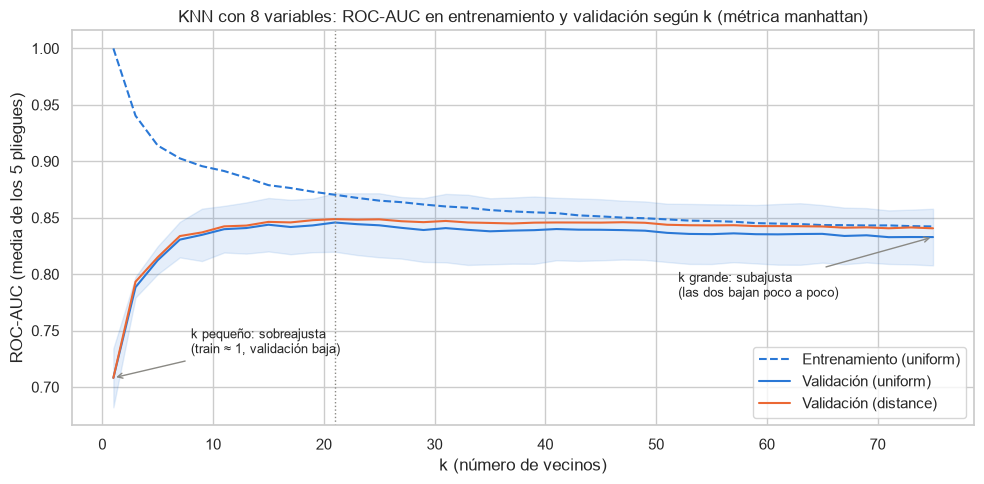

uniform: k = 1 → train 1,000, validación 0,708
uniform: mejor k = 21 → validación 0,846
uniform: k = 75 → train 0,842, validación 0,833
distance: el entrenamiento da siempre 1,000 (cada punto es su propio vecino a distancia 0)


In [11]:
metrica_mejor = busqueda_completo.best_params_["modelo__metric"]
curva = {w: res[(res["param_modelo__weights"] == w) & (res["param_modelo__metric"] == metrica_mejor)]
         .sort_values("param_modelo__n_neighbors") for w in ["uniform", "distance"]}

fig, ax = plt.subplots(figsize=(10, 5))
u, d = curva["uniform"], curva["distance"]
ax.plot(u["param_modelo__n_neighbors"], u["mean_train_score"], color=AZUL, ls="--", label="Entrenamiento (uniform)")
ax.plot(u["param_modelo__n_neighbors"], u["mean_test_score"], color=AZUL, label="Validación (uniform)")
ax.plot(d["param_modelo__n_neighbors"], d["mean_test_score"], color=NARANJA, label="Validación (distance)")
ax.fill_between(u["param_modelo__n_neighbors"].astype(float), u["mean_test_score"] - u["std_test_score"],
                u["mean_test_score"] + u["std_test_score"], color=AZUL, alpha=0.12)
k_mejor_u = int(u.loc[u["mean_test_score"].idxmax(), "param_modelo__n_neighbors"])
ax.axvline(k_mejor_u, color=GRIS, ls=":", lw=1)
ax.annotate("k pequeño: sobreajusta\n(train ≈ 1, validación baja)", xy=(1, u["mean_test_score"].iloc[0]),
            xytext=(8, 0.73), arrowprops=dict(arrowstyle="->", color=GRIS), fontsize=9)
ax.annotate("k grande: subajusta\n(las dos bajan poco a poco)", xy=(75, u["mean_test_score"].iloc[-1]),
            xytext=(52, 0.78), arrowprops=dict(arrowstyle="->", color=GRIS), fontsize=9)
ax.set_xlabel("k (número de vecinos)")
ax.set_ylabel("ROC-AUC (media de los 5 pliegues)")
ax.set_title(f"KNN con 8 variables: ROC-AUC en entrenamiento y validación según k (métrica {metrica_mejor})")
ax.legend(loc="lower right")
fig.tight_layout()
guardar(fig, "k")
plt.show()

print(f"uniform: k = 1 → train {num(u['mean_train_score'].iloc[0], 3)}, validación {num(u['mean_test_score'].iloc[0], 3)}")
print(f"uniform: mejor k = {k_mejor_u} → validación {num(u['mean_test_score'].max(), 3)}")
print(f"uniform: k = 75 → train {num(u['mean_train_score'].iloc[-1], 3)}, validación {num(u['mean_test_score'].iloc[-1], 3)}")
print(f"distance: el entrenamiento da siempre {num(d['mean_train_score'].min(), 3)} (cada punto es su propio vecino a distancia 0)")

**Conclusión.** Es el mismo dibujo que en el ejercicio de Iris de clase:

| | Iris (clase) | Recompra (aquí, uniform) |
|---|---|---|
| k = 1 | 100 % en train: sobreajusta | train ≈ 1 y la validación es la peor de todas |
| k intermedio | k = 9 era la mejor (95,6 %) | la validación sube rápido y se estabiliza en una meseta |
| k grande | k = 50 subajustaba | la validación baja poco a poco: el voto mezcla clientes muy distintos |

Con `weights="distance"` la curva de entrenamiento no sirve para ver el sobreajuste: siempre da 1,
porque cada cliente es su propio vecino más cercano y su voto pesa infinito. Por eso el gráfico usa
la de `uniform`. Aquí los mejores k son mucho mayores que en Iris porque hay más filas (unas 900 por
pliegue frente a 150 flores) y las clases se solapan mucho más.

## 5. Selección de variables (solo con la validación cruzada del entrenamiento)

Se comparan cuatro conjuntos, cada uno con su propia búsqueda de k, pesos y métrica:

- **RFM básico:** recencia, frecuencia y monetario (lo de la S7).
- **RFM + `pedidos_por_mes`:** la frecuencia relativa a la antigüedad. En la S7 se vio que la
  frecuencia acumulada no distingue "mucho tiempo comprando poco" de "poco tiempo comprando mucho".
- **Completo sin `pedidos_por_mes`**.
- **Completo:** las 8 variables.

**Regla fijada antes de mirar:** gana el conjunto con más ROC-AUC de validación; si otro con menos
variables queda a menos de 0,005, se elige el más sencillo.

In [12]:
RFM = ["recencia_dias", "frecuencia", "monetario"]
CONJUNTOS = {
    "RFM básico": RFM,
    "RFM + pedidos_por_mes": RFM + ["pedidos_por_mes"],
    "Completo sin pedidos_por_mes": [v for v in VARIABLES_RECOMPRA if v != "pedidos_por_mes"],
    "Completo (8 variables)": VARIABLES_RECOMPRA,
}
busquedas = {n: (busqueda_completo if vs == VARIABLES_RECOMPRA else buscar_knn(vs)) for n, vs in CONJUNTOS.items()}
filas = []
for n, b in busquedas.items():
    r = b.cv_results_
    filas.append({"conjunto": n, "nº variables": len(CONJUNTOS[n]), "k": b.best_params_["modelo__n_neighbors"],
                  "weights": b.best_params_["modelo__weights"], "métrica": b.best_params_["modelo__metric"],
                  "ROC-AUC validación": b.best_score_, "desviación": r["std_test_score"][b.best_index_]})
comparacion = pd.DataFrame(filas).set_index("conjunto")

# Regla de elección: el mejor, salvo que uno más sencillo esté a menos de 0,005
mejor_auc = comparacion["ROC-AUC validación"].max()
candidatos = comparacion[comparacion["ROC-AUC validación"] >= mejor_auc - 0.005]
CONJUNTO_ELEGIDO = candidatos.sort_values(["nº variables", "ROC-AUC validación"], ascending=[True, False]).index[0]
VARIABLES_KNN = CONJUNTOS[CONJUNTO_ELEGIDO]
PARAMS_KNN = {k.replace("modelo__", ""): v for k, v in busquedas[CONJUNTO_ELEGIDO].best_params_.items()}
print("Conjunto elegido:", CONJUNTO_ELEGIDO, "→", VARIABLES_KNN)
print("Hiperparámetros:", PARAMS_KNN)
mejora = (comparacion.loc["RFM + pedidos_por_mes", "ROC-AUC validación"] - comparacion.loc["RFM básico", "ROC-AUC validación"])
print(f"pedidos_por_mes sobre el RFM básico: {'+' if mejora >= 0 else ''}{num(mejora, 3)} de ROC-AUC")
comparacion.round(3)

Conjunto elegido: RFM + pedidos_por_mes → ['recencia_dias', 'frecuencia', 'monetario', 'pedidos_por_mes']
Hiperparámetros: {'metric': 'euclidean', 'n_neighbors': 41, 'weights': 'distance'}
pedidos_por_mes sobre el RFM básico: +0,027 de ROC-AUC


,nº variables,k,weights,métrica,ROC-AUC validación,desviación
conjunto,,,,,,
RFM básico,3,55,uniform,euclidean,0.831,0.023
RFM + pedidos_por_mes,4,41,distance,euclidean,0.858,0.017
Completo sin pedidos_por_mes,7,21,distance,manhattan,0.847,0.021
Completo (8 variables),8,21,distance,manhattan,0.849,0.021


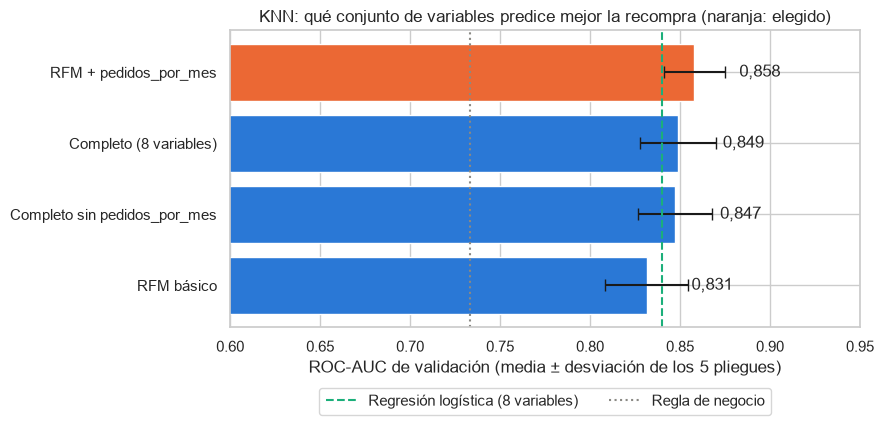

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
orden = comparacion.sort_values("ROC-AUC validación")
colores = [NARANJA if n == CONJUNTO_ELEGIDO else AZUL for n in orden.index]
ax.barh(orden.index, orden["ROC-AUC validación"], xerr=orden["desviación"], color=colores, capsize=4)
for i, v in enumerate(orden["ROC-AUC validación"]):
    ax.text(v + 0.025, i, num(v, 3), va="center")
ax.axvline(tabla_ref.loc["Regresión logística", "ROC-AUC (media CV)"], color=VERDE_AGUA, ls="--",
           label="Regresión logística (8 variables)")
ax.axvline(tabla_ref.loc["Regla: compró en 90 días", "ROC-AUC (media CV)"], color=GRIS, ls=":", label="Regla de negocio")
ax.set_xlim(0.6, 0.95)
ax.set_xlabel("ROC-AUC de validación (media ± desviación de los 5 pliegues)")
ax.set_title("KNN: qué conjunto de variables predice mejor la recompra (naranja: elegido)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
fig.tight_layout()
guardar(fig, "variables")
plt.show()

**Conclusión.** `pedidos_por_mes` es la variable que más aporta: añadida al RFM básico, la ROC-AUC
de validación sube 0,027 (de 0,831 a 0,858). Es la idea que quedó pendiente en la S7: la frecuencia
**relativa** a la antigüedad separa "mucho tiempo comprando poco" de "poco tiempo comprando mucho".
Las otras 4 variables no ayudan: el conjunto completo se queda en 0,849. En KNN cada variable de
más es una dimensión más en la distancia; si aporta poco, mete ruido en quién es "vecino" de quién.
La diferencia con el completo es menor que la desviación entre pliegues (0,017–0,021), así que no
es una gran victoria, pero la regla elige el mejor, que además es el más sencillo de los dos.

**KNN elegido:** RFM + `pedidos_por_mes`, k = 41, `weights="distance"`, distancia euclidea.

## 6. Umbral de decisión para la campaña de retención

**Caso de negocio:** la tienda quiere contactar (un descuento, un email) a los clientes que
probablemente **no** volverán. Un cliente está **en riesgo** si `prob_volver < umbral`.

- **Precision** de "en riesgo": de los contactados, cuántos de verdad no iban a volver (el resto es
  un descuento regalado a quien iba a comprar igual).
- **Recall** de "en riesgo": de los que no van a volver, a cuántos llegamos.

**Criterio fijado antes de mirar:** el umbral que **maximiza el F1 de la clase "no volverá"**, que
equilibra las dos. Se calcula con las predicciones de validación cruzada (`cross_val_predict`, cada
cliente predicho por un modelo que no lo ha visto), **nunca con la prueba**. Antes, se elige el modelo
que se va a usar: el de más ROC-AUC de validación entre la regresión logística y el KNN elegido.

In [14]:
knn_elegido = hacer_pipeline(VARIABLES_KNN, KNeighborsClassifier(**PARAMS_KNN))
auc_knn_cv = busquedas[CONJUNTO_ELEGIDO].best_score_
auc_log_cv = tabla_ref.loc["Regresión logística", "ROC-AUC (media CV)"]
MODELO_ELEGIDO = "KNN" if auc_knn_cv >= auc_log_cv else "Regresión logística"
print(f"ROC-AUC de validación: KNN {num(auc_knn_cv, 3)} · regresión logística {num(auc_log_cv, 3)} → modelo elegido: {MODELO_ELEGIDO}")

# Probabilidad de volver "fuera de muestra" para cada fila del entrenamiento
prob_cv = {
    "KNN": cross_val_predict(knn_elegido, X_train[VARIABLES_KNN], y_train, groups=grupos, cv=CV, method="predict_proba")[:, 1],
    "Regresión logística": cross_val_predict(logistica, X_train, y_train, groups=grupos, cv=CV, method="predict_proba")[:, 1],
}
UMBRALES = np.round(np.arange(0.05, 0.951, 0.01), 2)
no_vuelve = (y_train == 0).astype(int)   # la clase que interesa a la campaña


def curva_umbral(prob):
    filas = []
    for u in UMBRALES:
        en_riesgo = (prob < u).astype(int)
        filas.append({"umbral": u, "precision": precision_score(no_vuelve, en_riesgo, zero_division=0),
                      "recall": recall_score(no_vuelve, en_riesgo), "f1": f1_score(no_vuelve, en_riesgo),
                      "% contactados": en_riesgo.mean()})
    return pd.DataFrame(filas)


curvas = {n: curva_umbral(p) for n, p in prob_cv.items()}
UMBRAL = {n: float(c.loc[c["f1"].idxmax(), "umbral"]) for n, c in curvas.items()}
for n, c in curvas.items():
    f = c.loc[c["f1"].idxmax()]
    print(f"{n}: umbral = {num(f['umbral'], 2)} → F1 {num(f['f1'], 3)}, precision {pct(f['precision'])}, "
          f"recall {pct(f['recall'])}, contacta al {pct(f['% contactados'])} (validación cruzada)")

ROC-AUC de validación: KNN 0,858 · regresión logística 0,840 → modelo elegido: KNN


KNN: umbral = 0,59 → F1 0,738, precision 71,9 %, recall 75,8 %, contacta al 43,6 % (validación cruzada)
Regresión logística: umbral = 0,61 → F1 0,728, precision 67,3 %, recall 79,2 %, contacta al 48,7 % (validación cruzada)


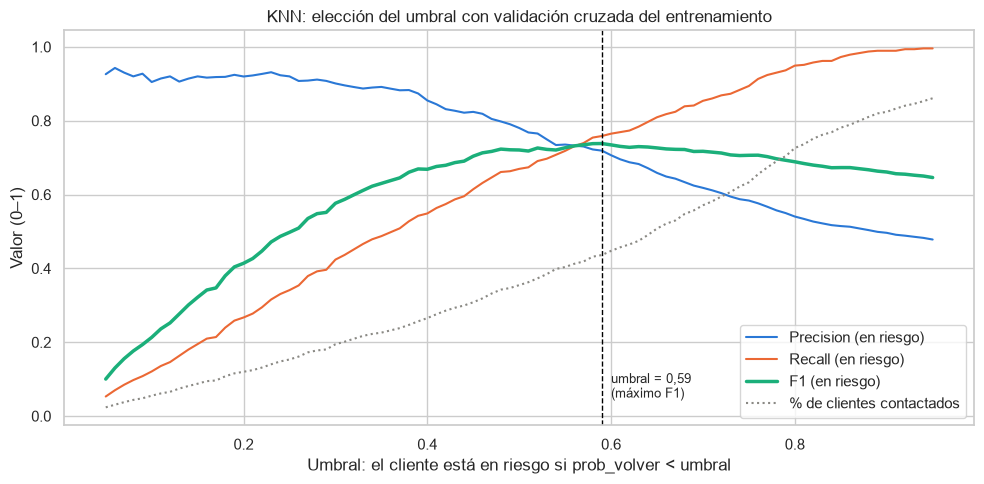

In [15]:
c = curvas[MODELO_ELEGIDO]
u = UMBRAL[MODELO_ELEGIDO]
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(c["umbral"], c["precision"], color=AZUL, label="Precision (en riesgo)")
ax.plot(c["umbral"], c["recall"], color=NARANJA, label="Recall (en riesgo)")
ax.plot(c["umbral"], c["f1"], color=VERDE_AGUA, lw=2.5, label="F1 (en riesgo)")
ax.plot(c["umbral"], c["% contactados"], color=GRIS, ls=":", label="% de clientes contactados")
ax.axvline(u, color="black", ls="--", lw=1)
ax.text(u + 0.01, 0.05, f"umbral = {num(u, 2)}\n(máximo F1)", fontsize=9)
ax.set_xlabel("Umbral: el cliente está en riesgo si prob_volver < umbral")
ax.set_ylabel("Valor (0–1)")
ax.set_title(f"{MODELO_ELEGIDO}: elección del umbral con validación cruzada del entrenamiento")
ax.legend(loc="lower right")
fig.tight_layout()
guardar(fig, "umbral")
plt.show()

**Conclusión.** Con el umbral 0,59, en la validación cruzada el KNN marca en riesgo al 43,6 % de los
clientes, con precision 71,9 % y recall 75,8 % (F1 0,738): de cada 10 contactados, unos 7 de verdad
no iban a volver, y se llega a 3 de cada 4 de los que se van. La curva de F1 es casi plana alrededor
del máximo: mover un poco el umbral cambia poco el F1, pero sí cuántos clientes se contactan. Si la
campaña tuviera un presupuesto limitado, se podría bajar el umbral para contactar a menos clientes
con más precision.

## 7. Evaluación final en la prueba (corte 2026-05-03, una sola vez)

Todos los modelos se entrenan con los 4 cortes de entrenamiento y se evalúan **una vez** con el
corte de la prueba. Las métricas de "en riesgo" (precision, recall, F1) usan el umbral de la
sección 6; la PR-AUC también se calcula para la clase "no volverá", la de la campaña.

In [16]:
dummy.fit(X_train, y_train)
logistica.fit(X_train, y_train)
knn_elegido.fit(X_train[VARIABLES_KNN], y_train)

prob_test = {
    "Dummy (mayoritaria)": dummy.predict_proba(X_test)[:, 1],
    "Regla: compró en 90 días": regla_negocio(X_test).astype(float),
    "Regresión logística": logistica.predict_proba(X_test)[:, 1],
    "KNN": knn_elegido.predict_proba(X_test[VARIABLES_KNN])[:, 1],
}
# Umbral de cada uno: el de la sección 6 para los modelos; la regla y el Dummy ya dan un 0/1
umbral_test = {"Dummy (mayoritaria)": 0.5, "Regla: compró en 90 días": 0.5,
               "Regresión logística": UMBRAL["Regresión logística"], "KNN": UMBRAL["KNN"]}
no_vuelve_test = (y_test == 0).astype(int)
filas = []
for n, p in prob_test.items():
    en_riesgo = (p < umbral_test[n]).astype(int)
    filas.append({"modelo": n, "umbral": umbral_test[n],
                  "ROC-AUC": roc_auc_score(y_test, p),
                  "PR-AUC (no volverá)": average_precision_score(no_vuelve_test, 1 - p),
                  "accuracy": accuracy_score(no_vuelve_test, en_riesgo),
                  "precision (no volverá)": precision_score(no_vuelve_test, en_riesgo, zero_division=0),
                  "recall (no volverá)": recall_score(no_vuelve_test, en_riesgo),
                  "F1 (no volverá)": f1_score(no_vuelve_test, en_riesgo),
                  "% contactados": en_riesgo.mean()})
tabla_test = pd.DataFrame(filas).set_index("modelo")
print(f"Prueba: {len(test)} clientes · {int(no_vuelve_test.sum())} no vuelven ({pct(no_vuelve_test.mean())}) "
      f"· PR-AUC del azar = {num(no_vuelve_test.mean(), 3)}")
print(f"Accuracy del Dummy: {num(tabla_test.loc['Dummy (mayoritaria)', 'accuracy'], 3)}")
tabla_test.round(3)

Prueba: 418 clientes · 186 no vuelven (44,5 %) · PR-AUC del azar = 0,445
Accuracy del Dummy: 0,555


,umbral,ROC-AUC,PR-AUC (no volverá),accuracy,precision (no volverá),recall (no volverá),F1 (no volverá),% contactados
modelo,,,,,,,,
Dummy (mayoritaria),0.50,0.500,0.445,0.555,0.000,0.000,0.000,0.000
Regla: compró en 90 días,0.50,0.729,0.629,0.737,0.726,0.656,0.689,0.402
Regresión logística,0.61,0.844,0.841,0.739,0.671,0.812,0.735,0.538
KNN,0.59,0.845,0.811,0.758,0.732,0.720,0.726,0.438


**Conclusión: ¿gana KNN?**

- **A la regla de negocio, sí, y con claridad:** ROC-AUC 0,845 frente a 0,729 y PR-AUC 0,811 frente
  a 0,629. Un modelo con varias variables ordena mucho mejor que un sí/no.
- **A la regresión logística, no.** Empatan en ROC-AUC (0,845 frente a 0,844), y la logística es
  **mejor** en PR-AUC (0,841 frente a 0,811) y en F1 (0,735 frente a 0,726). KNN solo gana en
  accuracy (0,758 frente a 0,739), porque con su umbral contacta a menos clientes (0,438 frente a
  0,538).
- Todos los modelos superan el accuracy del Dummy (0,555).

**Por qué KNN no supera a la logística.** La relación es casi "en una dirección": cuanto más
reciente y más frecuente es un cliente, más probable es que vuelva. Eso lo capta bien una recta
(en escala log), que es lo que hace la regresión logística. La ventaja de KNN es adaptarse a formas
raras, y aquí no las hay. Además, en la validación cruzada KNN parecía mejor (0,858 frente a 0,840),
pero se había quedado con la mejor de muchas combinaciones de variables, k, pesos y métricas, y la
mejor de muchas siempre sale algo inflada. En la prueba, esa ventaja desaparece.

El modelo elegido sigue siendo KNN, porque se eligió antes de mirar la prueba y cambiarlo ahora sería
elegirlo con ella. La logística sería una alternativa igual de buena y más fácil de explicar.

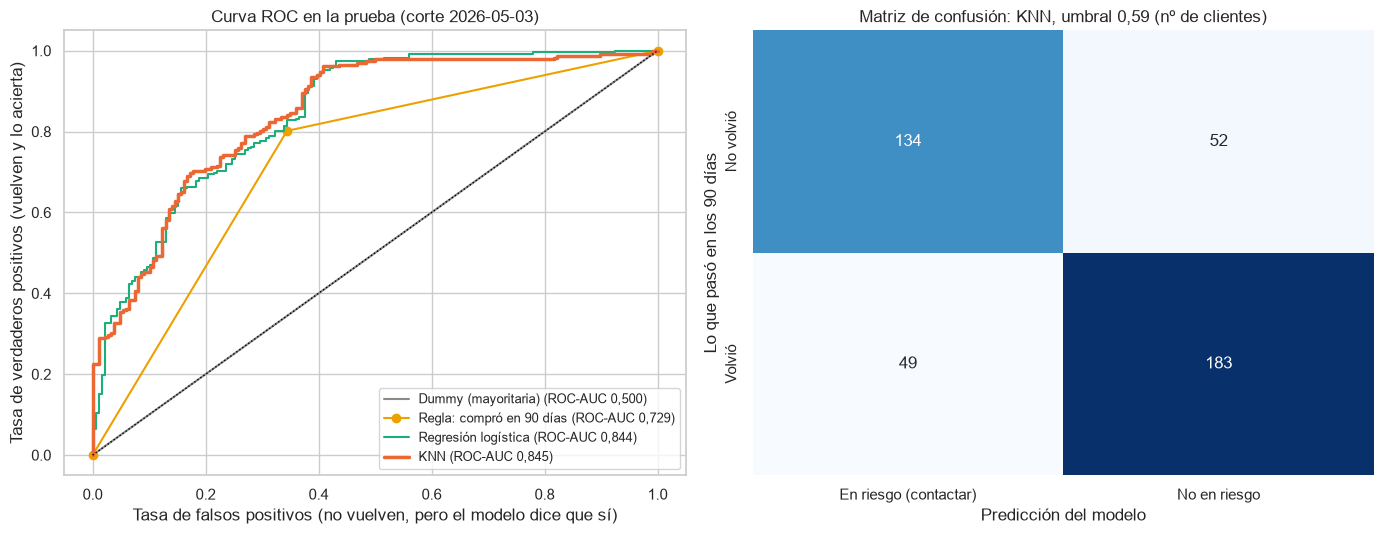

En riesgo y no volvió: 134 · en riesgo pero volvió: 49 · no en riesgo y no volvió: 52 · no en riesgo y volvió: 183


In [17]:
p_elegido = prob_test[MODELO_ELEGIDO]
en_riesgo_elegido = (p_elegido < umbral_test[MODELO_ELEGIDO]).astype(int)
fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))

# ROC de todos los modelos
for n, color in zip(prob_test, [GRIS, AMARILLO, VERDE_AGUA, NARANJA]):
    fpr, tpr, _ = roc_curve(y_test, prob_test[n])
    ejes[0].plot(fpr, tpr, color=color, lw=2.5 if n == MODELO_ELEGIDO else 1.5,
                 marker="o" if n.startswith("Regla") else None,
                 label=f"{n} (ROC-AUC {num(tabla_test.loc[n, 'ROC-AUC'], 3)})")
ejes[0].plot([0, 1], [0, 1], color="black", ls=":", lw=1)
ejes[0].set_xlabel("Tasa de falsos positivos (no vuelven, pero el modelo dice que sí)")
ejes[0].set_ylabel("Tasa de verdaderos positivos (vuelven y lo acierta)")
ejes[0].set_title("Curva ROC en la prueba (corte 2026-05-03)")
ejes[0].legend(loc="lower right", fontsize=9)

# Matriz de confusión del modelo elegido
mc = confusion_matrix(no_vuelve_test, en_riesgo_elegido, labels=[1, 0])
sns.heatmap(mc, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ejes[1],
            xticklabels=["En riesgo (contactar)", "No en riesgo"], yticklabels=["No volvió", "Volvió"])
ejes[1].set_xlabel("Predicción del modelo")
ejes[1].set_ylabel("Lo que pasó en los 90 días")
ejes[1].set_title(f"Matriz de confusión: {MODELO_ELEGIDO}, umbral {num(umbral_test[MODELO_ELEGIDO], 2)} (nº de clientes)")
fig.tight_layout()
guardar(fig, "roc_matriz")
plt.show()
vp, fn, fp, vn = mc[0, 0], mc[0, 1], mc[1, 0], mc[1, 1]
print(f"En riesgo y no volvió: {vp} · en riesgo pero volvió: {fp} · no en riesgo y no volvió: {fn} · no en riesgo y volvió: {vn}")

**Conclusión.** Las curvas de KNN y de la logística casi se superponen. La regla es un solo punto
(compró o no en 90 días) unido a las esquinas con rectas. En la matriz: de los 186 clientes que no
volvieron, KNN marcó en riesgo a 134 y se le escaparon 52. De los marcados, 49 volvieron igualmente:
para ellos el contacto (o el descuento) no hacía falta.

### Calibración: ¿una probabilidad de 0,7 significa un 70 %?

Un modelo está **calibrado** si, de los clientes a los que da un 70 % de probabilidad de volver,
vuelven de verdad unos 70 de cada 100. Se agrupan los clientes de la prueba por su probabilidad
(10 tramos con el mismo nº de clientes) y se compara la media predicha con la proporción real. Si
los puntos caen sobre la diagonal, la probabilidad se puede leer tal cual.

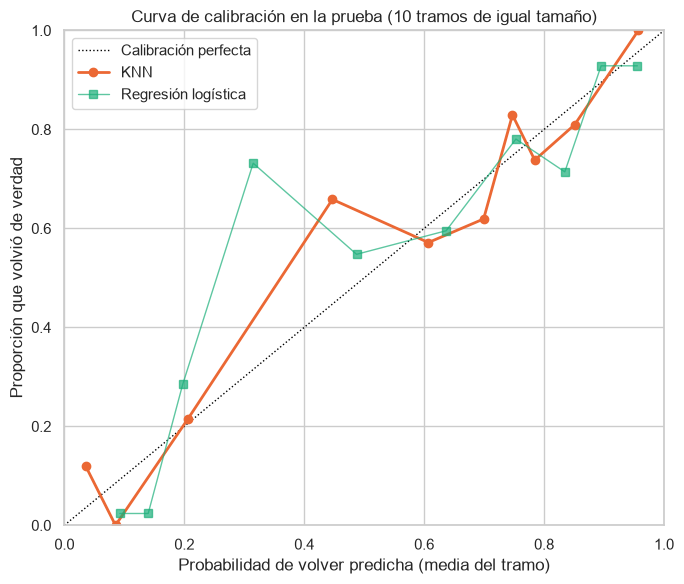

Brier (error cuadrático medio de la probabilidad, menor es mejor): KNN 0,153 · regresión logística 0,165
Diferencia media |predicha − real| por tramo: 0,072


In [18]:
real, predicha = calibration_curve(y_test, p_elegido, n_bins=10, strategy="quantile")
real_log, predicha_log = calibration_curve(y_test, prob_test["Regresión logística"], n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], color="black", ls=":", lw=1, label="Calibración perfecta")
ax.plot(predicha, real, marker="o", color=NARANJA, lw=2, label=MODELO_ELEGIDO)
if MODELO_ELEGIDO != "Regresión logística":
    ax.plot(predicha_log, real_log, marker="s", color=VERDE_AGUA, lw=1, alpha=0.7, label="Regresión logística")
ax.set_xlabel("Probabilidad de volver predicha (media del tramo)")
ax.set_ylabel("Proporción que volvió de verdad")
ax.set_title("Curva de calibración en la prueba (10 tramos de igual tamaño)")
ax.legend(loc="upper left")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
fig.tight_layout()
guardar(fig, "calibracion")
plt.show()
print(f"Brier (error cuadrático medio de la probabilidad, menor es mejor): {MODELO_ELEGIDO} "
      f"{num(brier_score_loss(y_test, p_elegido), 3)} · regresión logística "
      f"{num(brier_score_loss(y_test, prob_test['Regresión logística']), 3)}")
print("Diferencia media |predicha − real| por tramo:", num(np.abs(predicha - real).mean(), 3))

**Conclusión.** KNN está razonablemente calibrado: la diferencia media entre lo predicho y lo real
por tramo es de 0,072, y su Brier (0,153) es algo mejor que el de la logística (0,165). Algunos
tramos se alejan de la diagonal porque cada uno tiene pocos clientes y unos pocos mueven mucho el
punto. La probabilidad sirve sobre todo para **ordenar** a los clientes; leerla como un % exacto
sería pedirle demasiado con 418 clientes de prueba.

## 8. Modelo final y lista de acción

Se reentrena el modelo elegido, **con las mismas variables, hiperparámetros y umbral**, usando todos
los cortes con etiqueta: los 4 de entrenamiento, el de la prueba y el 2026-08-02 (el último con 90
días de futuro). k no se vuelve a buscar: elegirlo otra vez con la prueba dentro sería usarla para
decidir. Después se puntúa a los clientes con el corte 2026-11-01 (todos los pedidos hasta el
2026-10-31).

In [19]:
final = pd.concat([tabla_recompra(c, HORIZONTE) for c in CORTES_FINAL], ignore_index=True)
VARIABLES_FINAL = VARIABLES_KNN if MODELO_ELEGIDO == "KNN" else VARIABLES_RECOMPRA
if MODELO_ELEGIDO == "KNN":
    modelo_final = hacer_pipeline(VARIABLES_FINAL, KNeighborsClassifier(**PARAMS_KNN))
else:
    modelo_final = hacer_pipeline(VARIABLES_FINAL, LogisticRegression(max_iter=1000))
modelo_final.fit(final[VARIABLES_FINAL], final["volvera"])
print(f"Reentrenado con {len(final)} filas de {len(CORTES_FINAL)} cortes ({final['id_cliente'].nunique()} clientes distintos)")

actual = tabla_recompra(CORTE_PUNTUAR, HORIZONTE)
actual["prob_volver"] = modelo_final.predict_proba(actual[VARIABLES_FINAL])[:, 1]
actual["en_riesgo"] = (actual["prob_volver"] < UMBRAL[MODELO_ELEGIDO]).astype(int)
print(f"Clientes puntuados (corte {CORTE_PUNTUAR}): {len(actual)} · sin compras, fuera: {actual.attrs['n_sin_compras_antes']}")
print(f"En riesgo (prob_volver < {num(UMBRAL[MODELO_ELEGIDO], 2)}): {actual['en_riesgo'].sum()} ({pct(actual['en_riesgo'].mean())})")
print(f"Gasto histórico de los clientes en riesgo: {euros(actual.loc[actual['en_riesgo'] == 1, 'monetario'].sum())} "
      f"({pct(actual.loc[actual['en_riesgo'] == 1, 'monetario'].sum() / actual['monetario'].sum())} del total)")

Reentrenado con 2020 filas de 6 cortes (460 clientes distintos)
Clientes puntuados (corte 2026-11-01): 474 · sin compras, fuera: 19
En riesgo (prob_volver < 0,59): 187 (39,5 %)
Gasto histórico de los clientes en riesgo: 139.479 € (15,8 % del total)


### Recuperables o probablemente perdidos

"En riesgo" mezcla dos situaciones muy distintas. Hay clientes que llevan unos meses sin comprar,
a los que un contacto todavía puede hacer volver, y clientes que no compran desde hace años, para
los que una campaña de **retención** llega tarde. Se separan con una **regla de negocio fija**,
escrita antes de mirar el resultado y sin usar la verdad:

| Grupo (`accion`) | Regla |
|---|---|
| **Recuperable** → candidato a la campaña | en riesgo y `recencia_dias` < 365 |
| **Probablemente perdido** | en riesgo y `recencia_dias` ≥ 365 |
| **No en riesgo** | `prob_volver` ≥ umbral |

**Por qué 365 días.** Un año sin comprar es un corte fácil de explicar a negocio: el cliente se ha
saltado un ciclo completo, Navidad incluida, que es cuando más se vende. Además es coherente con la
S7: el segmento "Perdidos" tenía una mediana de recencia de 580 días, así que con 365 días quedan
como "probablemente perdidos" los clientes que ya se parecen a ese segmento, con margen. El 580 solo
se usa como referencia para justificar la regla: ni los segmentos ni ningún archivo de la S7 entran
en el modelo.

In [20]:
RECENCIA_PERDIDO = 365   # días sin comprar a partir de los cuales un cliente en riesgo se da por perdido


def accion(fila):
    """Regla de negocio fija: qué hacer con cada cliente."""
    if fila["en_riesgo"] == 0:
        return "No en riesgo"
    return "Recuperable" if fila["recencia_dias"] < RECENCIA_PERDIDO else "Probablemente perdido"


actual["accion"] = actual.apply(accion, axis=1)
grupos_accion = (actual.groupby("accion")
                 .agg(clientes=("id_cliente", "size"), gasto_historico=("monetario", "sum"),
                      prob_volver_media=("prob_volver", "mean"), recencia_mediana=("recencia_dias", "median"))
                 .reindex(["Recuperable", "Probablemente perdido", "No en riesgo"]))
grupos_accion["% clientes"] = (100 * grupos_accion["clientes"] / len(actual)).round(1)
grupos_accion["% gasto"] = (100 * grupos_accion["gasto_historico"] / actual["monetario"].sum()).round(1)
assert grupos_accion.loc[["Recuperable", "Probablemente perdido"], "clientes"].sum() == actual["en_riesgo"].sum()
print(f"Regla: en riesgo y recencia < {RECENCIA_PERDIDO} días → Recuperable; ≥ {RECENCIA_PERDIDO} días → Probablemente perdido")
for g in ["Recuperable", "Probablemente perdido"]:
    print(f"{g}: {grupos_accion.loc[g, 'clientes']} clientes · {euros(grupos_accion.loc[g, 'gasto_historico'])} "
          f"de gasto histórico ({num(grupos_accion.loc[g, '% gasto'], 1)} % del total)")
grupos_accion.round(3)

Regla: en riesgo y recencia < 365 días → Recuperable; ≥ 365 días → Probablemente perdido
Recuperable: 95 clientes · 64.266 € de gasto histórico (7,3 % del total)
Probablemente perdido: 92 clientes · 75.212 € de gasto histórico (8,5 % del total)


,clientes,gasto_historico,prob_volver_media,recencia_mediana,% clientes,% gasto
accion,,,,,,
Recuperable,95,64266.35,0.302,175.0,20.0,7.3
Probablemente perdido,92,75212.23,0.045,551.0,19.4,8.5
No en riesgo,287,743881.96,0.778,25.0,60.5,84.2


In [21]:
riesgo_csv = actual[["id_cliente", "prob_volver", "en_riesgo", "accion", "monetario"]].copy()
riesgo_csv["prob_volver"] = riesgo_csv["prob_volver"].round(6)
riesgo_csv["monetario"] = riesgo_csv["monetario"].round(2)
ruta_csv = RAIZ / "data" / "processed" / "riesgo_recompra.csv"
riesgo_csv.to_csv(ruta_csv, index=False, lineterminator="\n")
print("CSV guardado en", ruta_csv.relative_to(RAIZ), "·", len(riesgo_csv), "filas")

# Los 15 clientes más valiosos (más gasto) entre los RECUPERABLES: la lista de la campaña
top15 = (actual[actual["accion"] == "Recuperable"]
         .sort_values(["monetario", "id_cliente"], ascending=[False, True]).head(15)
         [["id_cliente", "prob_volver", "monetario", "frecuencia", "recencia_dias", "pedidos_por_mes", "ticket_medio"]])
print(f"Los 15 suman {euros(top15['monetario'].sum())} de gasto histórico · recencia de "
      f"{top15['recencia_dias'].min()} a {top15['recencia_dias'].max()} días · prob_volver de "
      f"{num(top15['prob_volver'].min(), 3)} a {num(top15['prob_volver'].max(), 3)}")
top15.round(3).reset_index(drop=True)

CSV guardado en data\processed\riesgo_recompra.csv · 474 filas
Los 15 suman 38.210 € de gasto histórico · recencia de 140 a 328 días · prob_volver de 0,159 a 0,575


,id_cliente,prob_volver,monetario,frecuencia,recencia_dias,pedidos_por_mes,ticket_medio
0,199,0.407,11026.56,5,140,0.352,2205.312
1,210,0.324,3487.00,24,305,1.005,145.292
2,15,0.533,3065.93,26,198,1.118,117.920
3,311,0.462,3049.52,24,239,1.039,127.063
4,382,0.575,2517.33,27,204,1.146,93.234
5,404,0.417,2162.61,19,250,0.802,113.822
6,42,0.360,1898.62,4,167,0.254,474.655
7,461,0.335,1789.81,8,222,0.449,223.726
8,445,0.220,1755.30,4,249,0.249,438.825
9,345,0.366,1616.07,5,160,0.832,323.214


**Conclusión.** Los 187 clientes en riesgo se reparten casi a partes iguales:

- **95 recuperables** (20,0 % de los clientes, 64.266 € de gasto histórico). Llevan una mediana de
  175 días sin comprar y tienen una probabilidad media de volver de 0,302. Son los candidatos a la
  campaña.
- **92 probablemente perdidos** (19,4 %, 75.212 €). Llevan una mediana de 551 días sin comprar,
  cerca de los 580 de los "Perdidos" de la S7, y su probabilidad media es de solo 0,045. Gastaron
  más en el pasado, pero una campaña de retención llega tarde: si se les contacta, sería con una
  acción distinta (reactivación) y solo a los que más gastaron.

Los 15 recuperables más valiosos suman 38.210 € y llevan entre 140 y 328 días sin comprar. Su
probabilidad de volver va de 0,159 a 0,575: todavía no se han ido. El primero, el cliente 199, tiene
un ticket medio muy alto (2205.312 €) con solo 5 pedidos. El resto son clientes con 4–27 pedidos
que han dejado de comprar hace unos meses.

In [22]:
nombre_archivo = "recompra_knn.joblib" if MODELO_ELEGIDO == "KNN" else "recompra_logistica.joblib"
paquete = {
    "pipeline": modelo_final,
    "modelo": MODELO_ELEGIDO,
    "variables": VARIABLES_FINAL,
    "hiperparametros": PARAMS_KNN if MODELO_ELEGIDO == "KNN" else {"max_iter": 1000},
    "umbral": UMBRAL[MODELO_ELEGIDO],
    "regla_umbral": "en_riesgo si prob_volver < umbral (máximo F1 de 'no volverá' en validación cruzada)",
    "horizonte_dias": HORIZONTE,
    "cortes_entrenamiento": CORTES_FINAL,
    "datos_hasta": str(DATOS_HASTA.date()),
}
ruta_modelo = CARPETA_MODELOS / nombre_archivo
joblib.dump(paquete, ruta_modelo)
print("Modelo guardado en", ruta_modelo.relative_to(RAIZ))

# Comprobación: se carga, da las mismas probabilidades y puntúa clientes "nuevos"
cargado = joblib.load(ruta_modelo)
assert np.allclose(cargado["pipeline"].predict_proba(actual[cargado["variables"]])[:, 1], actual["prob_volver"])
ejemplo = pd.DataFrame({"recencia_dias": [10, 300], "frecuencia": [25, 2], "monetario": [3500.0, 120.0],
                        "antiguedad_dias": [600, 650], "pedidos_por_mes": [1.25, 0.09], "ticket_medio": [140.0, 60.0],
                        "pedidos_ultimos_90d": [4, 0], "pct_cancelados_devueltos": [5.0, 0.0]},
                       index=["compra a menudo", "compró hace 300 días"])
p_ej = cargado["pipeline"].predict_proba(ejemplo[cargado["variables"]])[:, 1]
for nombre, p in zip(ejemplo.index, p_ej):
    print(f"Cliente que {nombre:<22} → prob_volver = {num(p, 3)} → {'EN RIESGO' if p < cargado['umbral'] else 'no en riesgo'}")
print("Umbral:", num(cargado["umbral"], 2), "· horizonte:", cargado["horizonte_dias"], "días · datos_hasta =", cargado["datos_hasta"])

Modelo guardado en models\recompra_knn.joblib
Cliente que compra a menudo        → prob_volver = 0,704 → no en riesgo
Cliente que compró hace 300 días   → prob_volver = 0,021 → EN RIESGO
Umbral: 0,59 · horizonte: 90 días · datos_hasta = 2026-10-31


## 9. COMPROBACIÓN CON LA VERDAD (solo informativa)

> **Esta es la única celda que lee la lista real de tipos de cliente del generador.** Nada de lo de
> arriba la ha usado: ni las variables, ni k, ni el umbral, ni el modelo. Solo sirve para ver si el
> resultado tiene sentido.

**Qué cabría esperar:** los **fieles** compran a menudo, así que su probabilidad de volver debería
ser **alta**; los **puntuales** compran una o pocas veces, así que debería ser **baja**; los
**ocasionales**, en medio.

In [23]:
verdad = pd.read_csv(RAIZ / "data" / "raw" / "_verdad_clientes.csv")
con_verdad = actual.merge(verdad, on="id_cliente", how="left")
assert con_verdad["tipo_real"].notna().all()
(con_verdad.groupby("tipo_real")
    .agg(clientes=("id_cliente", "size"), prob_volver_media=("prob_volver", "mean"), pct_en_riesgo=("en_riesgo", "mean"))
    .assign(pct_en_riesgo=lambda t: (100 * t["pct_en_riesgo"]).round(1))
    .sort_values("prob_volver_media", ascending=False).round(3))

,clientes,prob_volver_media,pct_en_riesgo
tipo_real,,,
fiel,87,0.914,1.1
ocasional,237,0.669,17.7
puntual,150,0.122,96.0


**Conclusión.** Lo esperado se cumple. Los fieles tienen de media 0,914 de probabilidad de volver y
solo el 1,1 % está en riesgo. Los puntuales tienen 0,122, y el 96,0 % está en riesgo. Los
ocasionales quedan en medio (0,669 y 17,7 %). El modelo nunca ha visto estos tipos, solo el
comportamiento de compra, y aun así los separa. Esta tabla no se ha usado para elegir nada.

## 10. Conclusiones

1. **Respuesta a la pregunta de negocio:** con los datos hasta el 2026-10-31, de los 474 clientes con
   alguna compra, **187 (39,5 %) están en riesgo de no volver** en los próximos 90 días (139.479 € de
   gasto histórico). De ellos, **95 son recuperables** (menos de 365 días sin comprar, 64.266 €) y son
   los candidatos a la campaña. Los otros **92 probablemente ya se han perdido** (75.212 €). La lista,
   con la columna `accion`, está en `data/processed/riesgo_recompra.csv`, y los 15 recuperables más
   valiosos, en la sección 8.
2. **Sin fugas:** las variables solo usan pedidos anteriores a cada corte (comprobado a mano en 7
   cortes), la validación cruzada agrupa por cliente y la prueba es un corte posterior (2026-05-03)
   que se miró una sola vez.
3. **Punto de partida:** en la prueba vuelve el 55,5 % de los clientes, así que decir siempre
   "volverá" (Dummy) ya da un accuracy de 0,555.
4. **La variable que más aporta es `pedidos_por_mes`:** sube la ROC-AUC de validación de 0,831 (RFM
   básico) a 0,858. KNN usa RFM + `pedidos_por_mes` con k = 41 y `weights="distance"`.
5. **En la prueba, KNN no supera a la regresión logística:** ROC-AUC 0,845 frente a 0,844, y la
   logística gana en PR-AUC (0,841 frente a 0,811). Las dos superan con claridad a la regla de los 90
   días (ROC-AUC 0,729).
6. **Umbral 0,59** (máximo F1 de "no volverá" en validación cruzada). En la prueba da una precision de
   0,732 y un recall de 0,720, contactando al 43,8 % de los clientes.
7. **Las probabilidades tienen sentido:** Brier 0,153. En la comprobación informativa, los fieles
   reales tienen una probabilidad media de 0,914 y los puntuales de 0,122.